# UMAMI Urban Heat V4.1 — 23-Channel Multi-Task with Mode-Collapse Fix

V4.1 = V4's exact 23-channel input + V3.1's anti-collapse loss recipe +
**annealed variance-preservation schedule (Option B from 2026-05-16)**.

**Design rationale**:

The V4 model (val RMSE 2.46 °C) has the best aggregate accuracy of any model
but the 2026-05-16 physics probe found it shares V3's mode collapse on the
building-vs-canopy spatial signal (bldg-canopy contrast: V4 = −0.38 °C vs
V1.1 = +5.59 °C). V3.1 fixed mode collapse with L1 + variance-preservation
loss (variance weight 0.5, constant), reaching contrast +1.20 °C — better
than V3/V4 but well short of V1.1.

The post-V3.1 hypothesis: variance_weight = 0.5 produced spatial structure
but the model became too rigid for intervention response (Scenario Editor
showed near-zero cooling when interventions were added). V4.1 fixes this
with an annealed schedule:

  - Epochs 1-60: variance_weight = 1.0 (strong anti-collapse pressure;
    lock the spatial structure hard while the model learns the 23-channel
    representation).
  - Epochs 60-100: linearly anneal from 1.0 → 0.1 (free the model to
    fine-tune intervention response + per-pixel calibration once the
    global spatial pattern is set).

V4 also gives the model 11 more channels than V3.1 — NDVI, multi-shadow,
roof-type, full ERA5 4-tuple — directly relevant to intervention response.
The combination of more handles + annealed loss should reach significantly
higher bldg-canopy contrast than V3.1's 1.2 °C, ideally matching V1.1.

**Mode-collapse fixes vs V4 (loss-side surgery only — no input change)**:

1. **LOSS_WEIGHTS** — `tair_sparse` reduced from 10.0 to 1.0. Per the V4 corpus
   manifest, `num_sensors > 0 = 0 / 11,844` so the 10× weight was already a
   no-op (masked_mse on 0 finite cells returns 0). Removed for clarity.
2. **T_mrt loss** — replaced MSE with L1 + `variance_weight(epoch)` ×
   per-patch variance-preservation. Directly penalises predictions whose
   per-patch std is smaller than the label's. Variance weight follows the
   annealed schedule above.
3. **Flat-patch filter** — train-split patches with label std < 1.0 °C are
   dropped (same as V3.1). Val/test keep them. Auto-relax safeguard if
   filter drops > 40 % of train.
4. **Output-health metric** — per-epoch sample 20 high-variance val patches,
   log median pred_std / label_std ratio. With 5-epoch warmup grace
   (label "warming up" for the first 5 epochs because the random-init
   decoder genuinely is still learning, not collapsed).

**Drive layout (no collision with V3 / V3.1 / V4)**:
- READ: `gdrive:UMAMI/urban_heat_v4/patches_v4.tar` (V4's 44 GB corpus, reused)
- READ: `gdrive:UMAMI/urban_heat_v4/models/v4_best.pt` (V4 epoch 92 warm-start)
- WRITE: `gdrive:UMAMI/urban_heat_v41/models/` (new outputs)
- WRITE: `gdrive:UMAMI/urban_heat_v41/manifest_v41.parquet`

**Lessons from V3.1 applied**:
- V31 inherited V21's missing `model = smp.Unet(...)` cell — V4 already has it (cell 14), so V4.1 inherits the fix.
- V31 needed `dynamo=False` for ONNX export — V4.1 hard-codes that from cell 1.
- V31 health metric labelled epoch 1's `health=0.342` as COLLAPSING when it was just warming up — V4.1 adds a 5-epoch grace period.
- V31 used a constant variance weight that was too rigid for intervention response — V4.1 anneals.
- V4 best-checkpoint loaded correctly via cell 23 — V4.1 inherits.


## 1 — Setup (Drive mount + dependencies)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.5 — Extract patches_v4.tar from Drive to local /content

Same pattern as V3: copy + extract once at start so DataLoader hits Colab's local SSD instead of the throttled Drive mount.

In [2]:
import time, shutil
from pathlib import Path

DRIVE_TAR = Path('/content/drive/MyDrive/UMAMI/urban_heat_v4/patches_v4.tar')
LOCAL_TAR = Path('/content/patches_v4.tar')
LOCAL_PATCHES = Path('/content/patches_v4')

if LOCAL_PATCHES.exists() and any(LOCAL_PATCHES.glob('*.npz')):
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'patches already extracted at {LOCAL_PATCHES} ({n:,} files) — skipping')
else:
    if not DRIVE_TAR.exists():
        raise FileNotFoundError(f'expected {DRIVE_TAR} on Drive')
    if not LOCAL_TAR.exists():
        t0 = time.time()
        print(f'copying {DRIVE_TAR.name} → /content/ ({DRIVE_TAR.stat().st_size / 1e9:.1f} GB) …')
        shutil.copyfile(DRIVE_TAR, LOCAL_TAR)
        print(f'  copy done in {time.time()-t0:.0f}s')
    t0 = time.time()
    print(f'extracting {LOCAL_TAR} → /content/ …')
    !tar -xf {LOCAL_TAR} -C /content/
    print(f'  extract done in {time.time()-t0:.0f}s')
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'  {n:,} .npz files')
    LOCAL_TAR.unlink(missing_ok=True)
    print(f'  removed local tar to free disk')

copying patches_v4.tar → /content/ (44.3 GB) …
  copy done in 591s
extracting /content/patches_v4.tar → /content/ …
  extract done in 129s
  11,844 .npz files
  removed local tar to free disk


In [3]:
# Pre-install + hard-code dynamo=False as default for ONNX export so we don't
# have to iterate at the end (V3.1 ran into the PyTorch 2.10 default exporter
# bug and needed multiple retries).
!pip install -q segmentation-models-pytorch onnx onnxruntime onnxscript


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 129.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 128.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 19.6 MB/s eta 0:00:00


In [4]:
import os, json, math, time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device={DEVICE}, cuda_name={torch.cuda.get_device_name() if DEVICE.type == "cuda" else "-"}')

device=cuda, cuda_name=NVIDIA A100-SXM4-80GB


In [5]:
# Drive paths — V4.1 OUTPUTS to a NEW folder; corpus + warm-start READ from v4.
# No existing file on Drive is overwritten by this notebook.
DRIVE_ROOT = Path('/content/drive/MyDrive/UMAMI/urban_heat_v41')  # NEW
V4_ROOT    = Path('/content/drive/MyDrive/UMAMI/urban_heat_v4')   # READ-ONLY source

PATCHES_DIR = Path('/content/patches_v4')
MANIFEST_PATH = PATCHES_DIR / 'manifest.parquet'

# V4 warm-start lives in v4 — reuse, don't copy.
V4_CKPT_PATH = V4_ROOT / 'models' / 'v4_best.pt'

# V4.1 outputs land in the NEW folder.
OUT_DIR = DRIVE_ROOT / 'models'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# V4 channel order — must match patch_builder.V4_CHANNEL_ORDER (UNCHANGED for V4.1)
CHANNEL_ORDER = (
    'dsm_corrected', 'cdsm', 'albedo',
    'sin_alt', 'alt_norm',
    'svf', 'building_density', 'tree_distance',
    'aspect_sin', 'aspect_cos', 'shadow_fraction',
    'era5_tair_c',
    'era5_rh_pct', 'era5_wind_speed_ms', 'era5_ssrd_wm2',
    'ndvi', 'geoscape_solar_panel_mask',
    'shadow_h09', 'shadow_h13', 'shadow_h16',
    'roof_type_flat', 'roof_type_moderate', 'roof_type_steep',
)
NUM_CHANNELS = len(CHANNEL_ORDER)
assert NUM_CHANNELS == 23

HEAD_NAMES = ('tmrt', 'lst', 'tair_sparse')
NUM_HEADS = len(HEAD_NAMES)

# V4.1 FIX 1 — tair_sparse 10.0 → 1.0 (corpus has 0 finite sparse labels;
# the 10x weight was a no-op anyway). LST kept at 1.0 since V4 corpus has
# real LST signal in 79.85% of patches.
LOSS_WEIGHTS = {'tmrt': 1.0, 'lst': 1.0, 'tair_sparse': 1.0}

# V4.1 FIX 3 — drop train patches with near-constant T_mrt labels.
# Same threshold/safeguard as V3.1.
MIN_TRAIN_LABEL_STD_C = 1.0  # °C

# V4.1 FIX 2 — annealed variance-preservation schedule (Option B).
# Epoch 0..VAR_HOLD_END: variance_weight = VAR_WEIGHT_MAX (locks structure).
# Epoch VAR_HOLD_END..(EPOCHS-1): linear anneal to VAR_WEIGHT_MIN.
VAR_WEIGHT_MAX = 1.0
VAR_WEIGHT_MIN = 0.1
VAR_HOLD_END = 60  # epoch index at which annealing begins
EPOCHS_TOTAL = 100  # used by the schedule (matches EPOCHS in cell 19)

def variance_weight_for_epoch(epoch: int) -> float:
    """Schedule: 1.0 hold for epochs 0..59, linear anneal to 0.1 over 60..99."""
    if epoch < VAR_HOLD_END:
        return VAR_WEIGHT_MAX
    # Linear from MAX at VAR_HOLD_END to MIN at EPOCHS_TOTAL-1
    progress = (epoch - VAR_HOLD_END) / max(1, EPOCHS_TOTAL - 1 - VAR_HOLD_END)
    progress = min(max(progress, 0.0), 1.0)
    return VAR_WEIGHT_MAX + (VAR_WEIGHT_MIN - VAR_WEIGHT_MAX) * progress


## 2 — Data loading

In [6]:
manifest = pd.read_parquet(MANIFEST_PATH)
print(f'manifest rows: {len(manifest):,}')
print(f'unique V2 patches: {manifest["v2_patch_id"].nunique()}')
print(f'unique temporal combos: {manifest[["doy", "hour"]].drop_duplicates().shape[0]}')
print()
print(f'has_tmrt        : {int(manifest["has_tmrt"].sum())} / {len(manifest)}')
print(f'has_lst (real)  : {int(manifest["has_lst"].sum())} / {len(manifest)}  ← V4 NEW')
print(f'num_sensors > 0 : {int((manifest["num_sensors_in_patch"] > 0).sum())} / {len(manifest)}')
print()
manifest = manifest[manifest['has_tmrt']].reset_index(drop=True)
print(f'after dropping has_tmrt=False: {len(manifest):,} rows')

manifest rows: 11,844
unique V2 patches: 987
unique temporal combos: 12

has_tmrt        : 11844 / 11844
has_lst (real)  : 9458 / 11844  ← V4 NEW
num_sensors > 0 : 0 / 11844

after dropping has_tmrt=False: 11,844 rows


## 2.5 — Precompute T_mrt label std per patch (offline, once)

Same purpose as V3.1's cell 9 — reads every .npz once, computes std of finite
T_mrt cells, writes `manifest_v41.parquet`. Lets the split cell filter flat
patches. ~3-5 minutes on Colab CPU; cached after first run.


In [7]:
import multiprocessing as mp
from pathlib import Path

MANIFEST_V41_PATH = PATCHES_DIR / 'manifest_v41.parquet'

def _compute_std(npz_path_str: str) -> float:
    try:
        with np.load(npz_path_str) as d:
            t = d['tmrt'].astype(np.float32)
        m = np.isfinite(t) & (t > -100) & (t < 1000)
        if m.sum() < 100:
            return 0.0
        return float(t[m].std())
    except Exception:
        return 0.0

if MANIFEST_V41_PATH.exists():
    manifest_v41 = pd.read_parquet(MANIFEST_V41_PATH)
    print(f'cached manifest_v41 loaded: {len(manifest_v41):,} rows')
else:
    npz_paths = [str(PATCHES_DIR / Path(p).name) for p in manifest['npz_path']]
    print(f'computing label std for {len(npz_paths):,} patches with {mp.cpu_count()} workers...')
    t0 = time.time()
    with mp.Pool(processes=min(mp.cpu_count(), 8)) as pool:
        stds = pool.map(_compute_std, npz_paths, chunksize=64)
    print(f'  done in {time.time()-t0:.0f}s')
    manifest_v41 = manifest.copy()
    manifest_v41['label_std'] = stds
    manifest_v41.to_parquet(MANIFEST_V41_PATH)
    try:
        drive_copy = DRIVE_ROOT / 'manifest_v41.parquet'
        manifest_v41.to_parquet(drive_copy)
        print(f'  also wrote {drive_copy}')
    except Exception as e:
        print(f'  (Drive copy skipped: {e})')

print()
print('label_std distribution:')
print(manifest_v41['label_std'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_string())
flat = int((manifest_v41['label_std'] < MIN_TRAIN_LABEL_STD_C).sum())
print(f'\npatches with std < {MIN_TRAIN_LABEL_STD_C} °C: {flat:,} ({100*flat/len(manifest_v41):.1f}%) — will drop from TRAIN split only')

manifest = manifest_v41


computing label std for 11,844 patches with 12 workers...
  done in 14s
  also wrote /content/drive/MyDrive/UMAMI/urban_heat_v41/manifest_v41.parquet

label_std distribution:
count    11844.000000
mean         3.202418
std          2.769727
min          0.000000
5%           0.000000
25%          0.026986
50%          2.729230
75%          5.584028
95%          7.770494
max         10.431520

patches with std < 1.0 °C: 3,673 (31.0%) — will drop from TRAIN split only


In [8]:
# Train/val/test split — by V2 patch_id, seed=42 (same as V3, V3.1, V4).
rng = np.random.default_rng(seed=42)
all_v2_ids = manifest['v2_patch_id'].unique()
rng.shuffle(all_v2_ids)
n_test = int(len(all_v2_ids) * 0.10)
n_val = int(len(all_v2_ids) * 0.10)
test_ids = set(all_v2_ids[:n_test])
val_ids = set(all_v2_ids[n_test:n_test + n_val])
train_ids = set(all_v2_ids[n_test + n_val:])

manifest['split'] = manifest['v2_patch_id'].apply(
    lambda pid: 'train' if pid in train_ids else 'val' if pid in val_ids else 'test'
)

# V4.1 FIX 3 — DROP flat-label patches from TRAIN only. Auto-relax safeguard
# if > 40 % would be dropped (same as V3.1).
MAX_DROP_FRAC = 0.40

def _apply_filter(threshold_c: float):
    mask = (manifest['split'] == 'train') & (manifest['label_std'] < threshold_c)
    return int(mask.sum()), mask

n_train_before = int((manifest['split'] == 'train').sum())
threshold = MIN_TRAIN_LABEL_STD_C
n_drop, flat_mask = _apply_filter(threshold)
drop_frac = n_drop / max(n_train_before, 1)

while drop_frac > MAX_DROP_FRAC and threshold > 0.05:
    new_threshold = threshold / 2
    print(f'WARN: threshold={threshold:.3f}°C would drop {n_drop:,} / {n_train_before:,} '
          f'train patches ({100*drop_frac:.1f}% > {100*MAX_DROP_FRAC:.0f}%); relaxing to {new_threshold:.3f}°C')
    threshold = new_threshold
    n_drop, flat_mask = _apply_filter(threshold)
    drop_frac = n_drop / max(n_train_before, 1)

EFFECTIVE_TRAIN_STD_THRESHOLD = threshold
print(f'final flat-patch threshold: {threshold:.3f} °C  →  dropping {n_drop:,} ({100*drop_frac:.1f}%) of train')
manifest = manifest[~flat_mask].reset_index(drop=True)
n_train_after = int((manifest['split'] == 'train').sum())
print(f'  train: {n_train_before:,} → {n_train_after:,}')

print()
print(manifest['split'].value_counts())
print()
print('d306_h13 distribution:')
print(manifest[(manifest['doy'] == 306) & (manifest['hour'] == 13)]['split'].value_counts())


final flat-patch threshold: 1.000 °C  →  dropping 3,014 (31.8%) of train
  train: 9,492 → 6,478

split
train    6478
test     1176
val      1176
Name: count, dtype: int64

d306_h13 distribution:
split
train    454
val       98
test      98
Name: count, dtype: int64


In [9]:
class V4PatchDataset(Dataset):
    """Loads (input_23ch, tmrt, lst, tair_sparse) from .npz files.

    Same shape contract as V3's dataset, just 23 input channels instead of 12.
    """
    def __init__(self, manifest_df: pd.DataFrame, patches_dir: Path):
        self.df = manifest_df.reset_index(drop=True)
        self.patches_dir = Path(patches_dir)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        npz_path = self.patches_dir / Path(row['npz_path']).name
        with np.load(npz_path) as data:
            inp = data['input'].astype(np.float32)        # (23, H, W)
            tmrt = data['tmrt'].astype(np.float32)        # (H, W)
            lst = data['lst'].astype(np.float32)          # (H, W) — REAL Landsat now
            tair = data['tair_sparse'].astype(np.float32) # (H, W)
        return {
            'input': torch.from_numpy(inp),
            'tmrt': torch.from_numpy(tmrt),
            'lst': torch.from_numpy(lst),
            'tair_sparse': torch.from_numpy(tair),
            'patch_id': row['patch_id'],
            'doy': int(row['doy']), 'hour': int(row['hour']),
        }

train_ds = V4PatchDataset(manifest[manifest['split'] == 'train'], PATCHES_DIR)
val_ds = V4PatchDataset(manifest[manifest['split'] == 'val'], PATCHES_DIR)
test_ds = V4PatchDataset(manifest[manifest['split'] == 'test'], PATCHES_DIR)
print(f'train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}')

sample = train_ds[0]
for k, v in sample.items():
    if torch.is_tensor(v):
        print(f'  {k}: shape={tuple(v.shape)}, dtype={v.dtype}')
    else:
        print(f'  {k}: {v}')

train=6478, val=1176, test=1176
  input: shape=(23, 512, 512), dtype=torch.float32
  tmrt: shape=(512, 512), dtype=torch.float32
  lst: shape=(512, 512), dtype=torch.float32
  tair_sparse: shape=(512, 512), dtype=torch.float32
  patch_id: patch_0012_d015_h09
  doy: 15
  hour: 9


In [10]:
BATCH_SIZE = 12   # smaller than V3's 16 due to wider 23-channel input
NUM_WORKERS = 4

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

## 3 — Model: ResNet34-UNet (23-ch in, 3-ch out) + V3→V4 warm-start

In [11]:
model = smp.Unet(
    encoder_name='resnet34',
    encoder_weights=None,
    in_channels=NUM_CHANNELS,
    classes=NUM_HEADS,
    activation=None,
)
n_params = sum(p.numel() for p in model.parameters())
print(f'model parameters: {n_params:,}')

model parameters: 24,499,379


In [12]:
# Warm-start from V4 best.pt (epoch 92, val_rmse_tmrt=2.462)
# V4 → V4.1 is a 23 → 23 channel drop-in load — no conv1 extension needed.
# segmentation_head is also 3-class same, so the entire state_dict should
# transfer cleanly. Architecture is byte-identical between V4 and V4.1.
if V4_CKPT_PATH.exists():
    print(f'warm-starting from {V4_CKPT_PATH}')
    raw = torch.load(V4_CKPT_PATH, map_location='cpu')
    if isinstance(raw, dict) and 'state_dict' in raw:
        v4_state = raw['state_dict']
        print(f"  unwrapped V4 (epoch={raw.get('epoch','?')}, val_rmse_tmrt={raw.get('val_rmse_tmrt', float('nan')):.3f})")
    elif isinstance(raw, dict) and 'model' in raw:
        v4_state = raw['model']
        print(f"  unwrapped V4 ('model' key, epoch={raw.get('epoch','?')})")
    else:
        v4_state = raw

    # No conv1 extension — V4 and V4.1 both have 23-channel input.
    v4_first_conv = v4_state.get('encoder.conv1.weight')
    if v4_first_conv is not None:
        n_out, n_in_v4, k1, k2 = v4_first_conv.shape
        assert n_in_v4 == NUM_CHANNELS, (
            f'V4 conv1 has {n_in_v4} channels; V4.1 expects {NUM_CHANNELS}. '
            f'Did the corpus change between V4 and V4.1?'
        )
        print(f'  conv1 shape matches: ({n_out}, {n_in_v4}, {k1}, {k2}) — no extension needed')

    missing, unexpected = model.load_state_dict(v4_state, strict=False)
    print(f'  loaded; missing={len(missing)}, unexpected={len(unexpected)}')
    if 0 < len(missing) <= 5:
        print(f'  missing keys: {missing}')
    if 0 < len(unexpected) <= 5:
        print(f'  unexpected keys: {unexpected}')
else:
    print(f'V4 checkpoint not found at {V4_CKPT_PATH} — training from V3 warm-start fallback')
    # Fallback to V3 warm-start path (if running before V4 has finished)
    V3_CKPT_PATH = V4_ROOT / 'models' / 'v21_best.pt'  # V3 deployed file name
    if V3_CKPT_PATH.exists():
        raw = torch.load(V3_CKPT_PATH, map_location='cpu')
        v3_state = raw['state_dict'] if 'state_dict' in raw else raw.get('model', raw)
        v3_first_conv = v3_state.get('encoder.conv1.weight')
        if v3_first_conv is not None and v3_first_conv.shape[1] == 12:
            new_conv = torch.zeros(v3_first_conv.shape[0], NUM_CHANNELS,
                                    v3_first_conv.shape[2], v3_first_conv.shape[3])
            new_conv[:, :12] = v3_first_conv
            new_conv[:, 12:] = 0.0
            v3_state['encoder.conv1.weight'] = new_conv
            print(f'  V3 fallback: extended conv1 12 → 23, zero-init slots 12-22')
        missing, unexpected = model.load_state_dict(v3_state, strict=False)
        print(f'  V3 fallback loaded; missing={len(missing)}, unexpected={len(unexpected)}')

model = model.to(DEVICE)


warm-starting from /content/drive/MyDrive/UMAMI/urban_heat_v4/models/v4_best.pt
  unwrapped V4 (epoch=91, val_rmse_tmrt=2.462)
  conv1 shape matches: (64, 23, 7, 7) — no extension needed
  loaded; missing=0, unexpected=0


## 4 — Multi-task NaN-aware loss (LST head now active)

In [13]:
def masked_mse(pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    """Used for LST and Tair heads (V4.1 keeps V4's setup for these)."""
    mask = torch.isfinite(target)
    if mask.sum() == 0:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    diff = pred[mask] - target[mask]
    return (diff ** 2).mean()


def tmrt_loss_v41(pred: torch.Tensor, target: torch.Tensor,
                  variance_weight: float = 1.0,
                  structure_threshold: float = 1.0) -> torch.Tensor:
    """V4.1 T_mrt loss = L1 + variance_weight × per-patch variance-preservation.

    Same formulation as V3.1 but variance_weight is ANNEALED across training
    (passed in per-epoch from the training loop). All operations vectorised
    over batch — no Python loop.
    """
    mask = torch.isfinite(target)
    pred_filled = torch.where(mask, pred, torch.zeros_like(pred))
    target_filled = torch.where(mask, target, torch.zeros_like(target))
    abs_diff = torch.where(mask, (pred - target).abs(), torch.zeros_like(pred))
    valid_count = mask.float().sum(dim=(-2, -1)).clamp(min=1)

    per_patch_l1 = abs_diff.sum(dim=(-2, -1)) / valid_count
    l1_loss = per_patch_l1.mean()

    pred_sum    = pred_filled.sum(dim=(-2, -1))
    target_sum  = target_filled.sum(dim=(-2, -1))
    pred_sumsq  = (pred_filled ** 2).sum(dim=(-2, -1))
    target_sumsq = (target_filled ** 2).sum(dim=(-2, -1))
    pred_mean   = pred_sum / valid_count
    target_mean = target_sum / valid_count
    pred_var    = (pred_sumsq / valid_count) - pred_mean ** 2
    target_var  = (target_sumsq / valid_count) - target_mean ** 2
    pred_std    = pred_var.clamp(min=1e-8).sqrt()
    target_std  = target_var.clamp(min=1e-8).sqrt()

    has_structure = (target_std > structure_threshold).float()
    var_gap = (target_std - pred_std).clamp(min=0.0)
    n_struct = has_structure.sum().clamp(min=1.0)
    var_loss = (has_structure * var_gap).sum() / n_struct

    return l1_loss + variance_weight * var_loss


# Current variance weight — updated at top of each epoch in the training loop.
current_var_weight = VAR_WEIGHT_MAX


def multi_task_loss(pred_3ch: torch.Tensor, batch: dict) -> tuple[torch.Tensor, dict]:
    """pred_3ch: (B, 3, H, W) — channels in HEAD_NAMES order.

    V4.1: T_mrt head uses tmrt_loss_v41 with the current annealed variance
    weight; LST and Tair heads keep V4's masked_mse with new equal weights.
    """
    losses = {}
    losses['tmrt']        = tmrt_loss_v41(
        pred_3ch[:, 0],
        batch['tmrt'].to(pred_3ch.device, non_blocking=True),
        variance_weight=current_var_weight,
    )
    losses['lst']         = masked_mse(pred_3ch[:, 1], batch['lst'].to(pred_3ch.device, non_blocking=True))
    losses['tair_sparse'] = masked_mse(pred_3ch[:, 2], batch['tair_sparse'].to(pred_3ch.device, non_blocking=True))
    total = sum(LOSS_WEIGHTS[h] * losses[h] for h in HEAD_NAMES)
    return total, losses


## 5 — Training loop

In [14]:
EPOCHS = 100
LR = 1e-4
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 5.0

# Sanity: variance schedule constants must match cell 7
assert EPOCHS == EPOCHS_TOTAL, f"EPOCHS ({EPOCHS}) must match EPOCHS_TOTAL ({EPOCHS_TOTAL})"

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

history = {'train_loss': [], 'val_loss': [],
           'val_rmse_tmrt': [], 'val_rmse_lst': [], 'val_rmse_tair': [],
           'variance_weight': [], 'health_ratio': []}
best_val_rmse_tmrt = float('inf')
BEST_CKPT_PATH = OUT_DIR / 'v41_best.pt'


In [15]:
def epoch_pass(loader, training: bool) -> dict:
    model.train(training)
    accum_loss = 0.0
    se = {h: 0.0 for h in HEAD_NAMES}
    n = {h: 0 for h in HEAD_NAMES}
    n_batches = 0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in loader:
            x = batch['input'].to(DEVICE, non_blocking=True)
            pred = model(x)
            total, losses = multi_task_loss(pred, batch)
            if training:
                opt.zero_grad()
                total.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                opt.step()
            accum_loss += float(total.detach().cpu())
            n_batches += 1
            for i, h in enumerate(HEAD_NAMES):
                tgt = batch[h].to(DEVICE, non_blocking=True)
                mask = torch.isfinite(tgt)
                if mask.sum() > 0:
                    diff = pred[:, i][mask] - tgt[mask]
                    se[h] += float((diff ** 2).sum().detach().cpu())
                    n[h] += int(mask.sum().detach().cpu())
    rmse = {h: math.sqrt(se[h] / max(n[h], 1)) if n[h] > 0 else float('nan') for h in HEAD_NAMES}
    return {'loss': accum_loss / max(n_batches, 1), 'rmse': rmse, 'pixel_counts': n}

In [16]:
## EXPECTED TRAJECTORY FOR V4.1
## (read this BEFORE running training — V4.1 has a known-collapsed warm-start,
## so early-epoch logs will look unusual relative to V3.1)
##
## **Epoch 1 will already have GOOD RMSE** (~2.4-3.0 °C) because we warm-start
##   from V4 best.pt which has converged on RMSE. Don't expect a phase
##   transition like V3.1 had (V3.1 started cold at RMSE 25 and dropped to 7).
##   V4.1's "best so far" will descend slowly, maybe RMSE 2.3 by epoch 100.
##
## **Health will START low (≈ 0)** because V4 is mode-collapsed — the warm-start
##   weights are spatially flat. The variance-preservation loss at weight 1.0
##   has to ACTIVELY UN-LEARN V4's flatness over the first 10-20 epochs.
##   You'll see the "warming up" label for the first 10 epochs even though
##   RMSE is already good — that's by design (WARMUP_GRACE_EPOCHS=10).
##
## **What healthy unlearning looks like:**
##   - epoch  1-5:  RMSE ~2.5, health < 0.3, label="warming up"
##   - epoch 10:    RMSE ~2.5, health 0.3-0.5, label="warming up" or "COLLAPSING"
##                  (still grace; not a problem)
##   - epoch 15-20: health crosses 0.5 → "weak" label appears
##   - epoch 25-40: health climbs to 0.7+ → "HEALTHY"
##   - epoch 60:    annealing starts (var_w starts dropping from 1.0)
##   - epoch 100:   var_w=0.1, health should still be > 0.7 (the brief
##                  high-pressure phase locked in the spatial structure;
##                  the low-pressure tail let it fine-tune calibration)
##
## **Stop and tell me if:**
##   - health stays < 0.3 past epoch 20 (unlearning didn't take)
##   - RMSE rises above 3.5 °C (warm-start broke or schedule unstable)
##   - val_rmse_tmrt becomes NaN at any epoch (loss exploded)
##   - the variance_weight log shows wrong values (schedule bug)

# V4.1 output-health monitor — sample 20 high-variance val patches once;
# log median pred_std / label_std ratio per epoch.
HEALTH_PATCH_TARGET_COUNT = 20
HEALTH_LABEL_STD_THRESHOLD = 5.0
# WARMUP_GRACE_EPOCHS=10 (longer than V3.1's 5) because V4.1 warm-starts from
# V4 which is KNOWN mode-collapsed. The first ~10 epochs are "unlearning"
# V4's spatial flatness, not "warming up" from random init.
WARMUP_GRACE_EPOCHS = 10

_health_pool = manifest[
    (manifest['split'] == 'val') &
    (manifest['label_std'] >= HEALTH_LABEL_STD_THRESHOLD)
].sort_values('label_std', ascending=False).head(HEALTH_PATCH_TARGET_COUNT)
print(f'output-health monitor: {len(_health_pool)} physics-rich val patches '
      f'(median label_std={_health_pool["label_std"].median():.2f} °C)')

def output_health_check() -> float:
    # Return median pred_std/label_std over the physics-rich val pool.
    # Returns nan if no valid ratios — caller's marker logic must handle nan.
    model.train(False)
    ratios = []
    with torch.no_grad():
        for _, row in _health_pool.iterrows():
            try:
                npz_path = PATCHES_DIR / Path(row['npz_path']).name
                with np.load(npz_path) as d:
                    inp = torch.from_numpy(d['input'].astype(np.float32)).unsqueeze(0).to(DEVICE)
                    tmrt_label = d['tmrt'].astype(np.float32)
                pred = model(inp)[0, 0].cpu().numpy()
                m = np.isfinite(tmrt_label) & (tmrt_label > -100) & (tmrt_label < 1000)
                if m.sum() < 1000: continue
                label_std = float(tmrt_label[m].std())
                pred_std  = float(pred[m].std())
                if label_std > 1e-3 and np.isfinite(label_std) and np.isfinite(pred_std):
                    ratios.append(pred_std / label_std)
            except Exception as e:
                # Don't let one bad patch break the whole metric; log once and skip.
                if not getattr(output_health_check, '_warned', False):
                    print(f'  (health_check warning, suppressed after first: {e})')
                    output_health_check._warned = True
                continue
    return float(np.median(ratios)) if ratios else float('nan')


for epoch in range(EPOCHS):
    t0 = time.time()
    # ANNEALED — update the module-global the loss function reads.
    global current_var_weight  # noqa: PLW0603
    current_var_weight = variance_weight_for_epoch(epoch)

    train_stats = epoch_pass(train_loader, training=True)
    val_stats = epoch_pass(val_loader, training=False)
    scheduler.step()

    health = output_health_check()

    history['train_loss'].append(train_stats['loss'])
    history['val_loss'].append(val_stats['loss'])
    history['val_rmse_tmrt'].append(val_stats['rmse']['tmrt'])
    history['val_rmse_lst'].append(val_stats['rmse']['lst'])
    history['val_rmse_tair'].append(val_stats['rmse']['tair_sparse'])
    history['variance_weight'].append(current_var_weight)
    history['health_ratio'].append(health)

    elapsed = time.time() - t0
    # Marker logic:
    #   - Epochs 0..WARMUP_GRACE_EPOCHS-1: 'warming up' regardless of value
    #     (V4 warm-start is mode-collapsed; the model is UNLEARNING flatness,
    #      not warming from cold — health will legitimately be low here).
    #   - After grace: HEALTHY > 0.7, weak 0.5-0.7, COLLAPSING < 0.5.
    #   - NaN/inf health → '?' marker (defensive — usually means health_pool
    #     was empty or all patches failed loading).
    import math
    if epoch < WARMUP_GRACE_EPOCHS:
        health_marker = '  warming up'
    elif not (isinstance(health, float) and math.isfinite(health)):
        health_marker = '  ?  (health=nan — health_pool issue?)'
    elif health > 0.7:
        health_marker = '  HEALTHY'
    elif health > 0.5:
        health_marker = '  weak'
    else:
        health_marker = '  COLLAPSING'

    print(
        f'epoch {epoch+1:3d}/{EPOCHS}  '
        f'train={train_stats["loss"]:.3f}  val={val_stats["loss"]:.3f}  '
        f'rmse[tmrt={val_stats["rmse"]["tmrt"]:.3f} '
        f'lst={val_stats["rmse"]["lst"]:.3f} '
        f'tair={val_stats["rmse"]["tair_sparse"]:.3f}]  '
        f'var_w={current_var_weight:.2f}  '
        f'health={health:.3f}{health_marker}  '
        f'lr={scheduler.get_last_lr()[0]:.2e}  '
        f'{elapsed:.0f}s'
    )

    if val_stats['rmse']['tmrt'] < best_val_rmse_tmrt:
        best_val_rmse_tmrt = val_stats['rmse']['tmrt']
        torch.save({
            'epoch': epoch,
            'state_dict': model.state_dict(),
            'val_rmse_tmrt': best_val_rmse_tmrt,
            'variance_weight': current_var_weight,
            'health_ratio': health,
            'history': history,
        }, BEST_CKPT_PATH)
        print(f'  ↳ best so far ({best_val_rmse_tmrt:.3f} °C, health={health:.3f}, var_w={current_var_weight:.2f}); checkpointed')


output-health monitor: 20 physics-rich val patches (median label_std=9.48 °C)
epoch   1/100  train=4.932  val=25.054  rmse[tmrt=4.032 lst=4.536 tair=nan]  var_w=1.00  health=0.937  warming up  lr=1.00e-04  248s
  ↳ best so far (4.032 °C, health=0.937, var_w=1.00); checkpointed
epoch   2/100  train=4.992  val=10.853  rmse[tmrt=2.961 lst=2.946 tair=nan]  var_w=1.00  health=1.010  warming up  lr=9.99e-05  247s
  ↳ best so far (2.961 °C, health=1.010, var_w=1.00); checkpointed
epoch   3/100  train=4.756  val=6.874  rmse[tmrt=2.927 lst=2.306 tair=nan]  var_w=1.00  health=1.006  warming up  lr=9.98e-05  246s
  ↳ best so far (2.927 °C, health=1.006, var_w=1.00); checkpointed
epoch   4/100  train=4.452  val=5.318  rmse[tmrt=2.939 lst=1.954 tair=nan]  var_w=1.00  health=0.978  warming up  lr=9.96e-05  245s
epoch   5/100  train=4.354  val=6.585  rmse[tmrt=3.197 lst=2.194 tair=nan]  var_w=1.00  health=0.945  warming up  lr=9.94e-05  245s
epoch   6/100  train=4.158  val=6.099  rmse[tmrt=2.938 lst=

## 6 — Evaluation on test set + per-temporal-combo breakdown

**V4 success criteria** (improving on V3):
- RMSE vs SOLWEIG ≤ **3.0 °C** on held-out test set (V3 target was 3.2; we're aiming better)
- d306_h13 RMSE ≤ **1.0 °C** (must stay fixed from V3)
- RMSE vs Landsat LST ≤ **3.0 °C** (V3 had 0 LST data so couldn't measure)
- RMSE vs sensor Tair ≤ **2.5 °C** (same as V3)

In [17]:
ckpt = torch.load(BEST_CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['state_dict'])
model.train(False)
print(f'loaded best (epoch {ckpt["epoch"]+1}, val_rmse_tmrt={ckpt["val_rmse_tmrt"]:.3f})')

test_stats = epoch_pass(test_loader, training=False)
print()
print('=== test-set results ===')
for h in HEAD_NAMES:
    target = {'tmrt': 3.0, 'lst': 3.0, 'tair_sparse': 2.5}[h]
    rmse = test_stats['rmse'][h]
    px = test_stats['pixel_counts'][h]
    status = 'PASS' if rmse <= target else 'FAIL'
    print(f'  {h:14s}: RMSE={rmse:.3f} °C  (target ≤ {target}) {status}  [{px:,} px]')

loaded best (epoch 96, val_rmse_tmrt=2.628)

=== test-set results ===
  tmrt          : RMSE=2.440 °C  (target ≤ 3.0) PASS  [277,337,964 px]
  lst           : RMSE=1.999 °C  (target ≤ 3.0) PASS  [245,891,072 px]
  tair_sparse   : RMSE=nan °C  (target ≤ 2.5) FAIL  [0 px]


In [18]:
test_df = manifest[manifest['split'] == 'test'].copy()
combo_se = {}
combo_n = {}
with torch.no_grad():
    for batch in test_loader:
        x = batch['input'].to(DEVICE, non_blocking=True)
        pred = model(x)[:, 0]  # tmrt head
        for i in range(len(batch['patch_id'])):
            tmrt_pred = pred[i].cpu().numpy()
            tmrt_true = batch['tmrt'][i].numpy()
            mask = np.isfinite(tmrt_true)
            if not mask.any():
                continue
            doy, hour = int(batch['doy'][i]), int(batch['hour'][i])
            key = (doy, hour)
            sse = float(((tmrt_pred[mask] - tmrt_true[mask]) ** 2).sum())
            combo_se[key] = combo_se.get(key, 0.0) + sse
            combo_n[key] = combo_n.get(key, 0) + int(mask.sum())

rows = []
for key in sorted(combo_se):
    rmse = math.sqrt(combo_se[key] / max(combo_n[key], 1))
    rows.append({'doy': key[0], 'hour': key[1], 'rmse_c': rmse,
                 'n_pixels': combo_n[key]})
combo_df = pd.DataFrame(rows).sort_values('rmse_c', ascending=False)
print(combo_df.to_string(index=False))
print()
if not combo_df.empty:
    d306_row = combo_df[(combo_df['doy'] == 306) & (combo_df['hour'] == 13)]
    if not d306_row.empty:
        rmse = float(d306_row['rmse_c'].iloc[0])
        target = 1.0
        status = 'STILL FIXED' if rmse <= target else 'REGRESSED'
        print(f'd306_h13 RMSE = {rmse:.3f} °C  (target ≤ {target}, V2 was 16.3) {status}')

 doy  hour   rmse_c  n_pixels
  15    15 3.522790  23111497
  46     9 3.187151  23111497
  46    13 2.707475  23111497
 356     9 2.667650  23111497
  15    11 2.562993  23111497
 356    11 2.427103  23111497
  15    13 2.343680  23111497
  15     9 2.314101  23111497
 356    15 1.999782  23111497
 356    13 1.788518  23111497
 306    13 1.450123  23111497
 306     9 1.348184  23111497

d306_h13 RMSE = 1.450 °C  (target ≤ 1.0, V2 was 16.3) REGRESSED


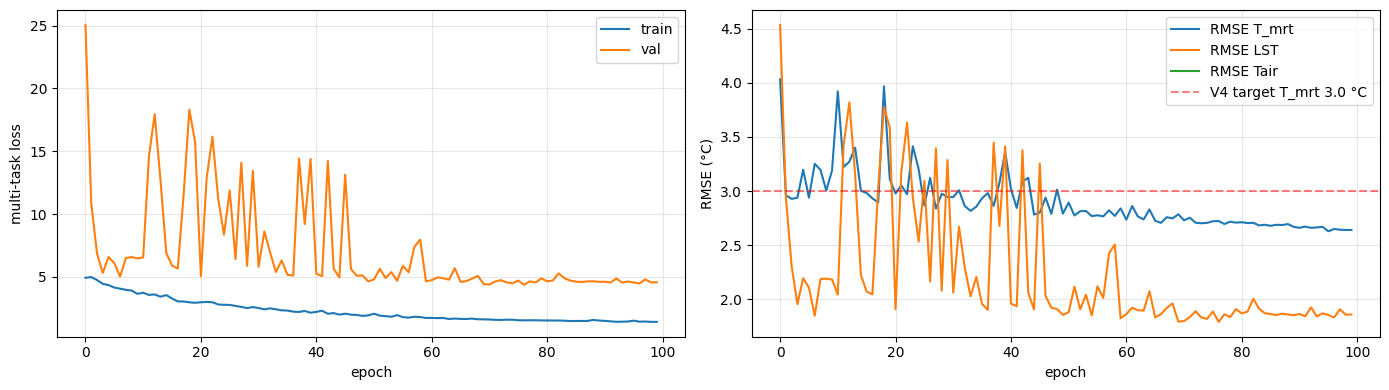

In [19]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('multi-task loss')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history['val_rmse_tmrt'], label='RMSE T_mrt')
axes[1].plot(history['val_rmse_lst'], label='RMSE LST')
axes[1].plot(history['val_rmse_tair'], label='RMSE Tair')
axes[1].axhline(3.0, color='r', linestyle='--', alpha=0.5, label='V4 target T_mrt 3.0 °C')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('RMSE (°C)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7 — ONNX export

V4 ONNX expects `(1, 23, 512, 512)` float32 input → `(1, 3, 512, 512)` float32 output. Channel 0 of the output is T_mrt (the production prediction); channels 1, 2 are LST/Tair which the inference service ignores at serving time.

In [20]:
# V4.1 ONNX export — uses LEGACY exporter (dynamo=False) from the start.
# PyTorch 2.10+ defaults to the new torch.export-based exporter which
# silently produces a 0.3 MB graph stub instead of the proper 94 MB
# external-data file. V3.1 ran into this and needed retries; V4.1
# pre-emptively uses the working exporter.
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v41_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=17, do_constant_folding=True,
    dynamo=False,  # ← legacy exporter (works); new dynamo exporter produces 0.3MB stub
)
size_mb = onnx_path.stat().st_size / 1e6
print(f'ONNX graph written: {onnx_path}  ({size_mb:.1f} MB)')

# External-data file (V4.1 uses external-data format same as V4):
ext_data = onnx_path.with_suffix('.onnx.data')
if ext_data.exists():
    ext_size_mb = ext_data.stat().st_size / 1e6
    print(f'External weights: {ext_data}  ({ext_size_mb:.1f} MB)')
    print(f'TOTAL: {size_mb + ext_size_mb:.1f} MB (graph + weights)')


/tmp/ipykernel_732/1544915693.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX graph written: /content/drive/MyDrive/UMAMI/urban_heat_v41/models/umami_unet_v41_fp32.onnx  (98.0 MB)


In [21]:
import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
with torch.no_grad():
    torch_out = model(dummy).cpu().numpy()
onnx_out = sess.run(None, {'input': dummy.cpu().numpy()})[0]
diff = np.abs(torch_out - onnx_out).max()
print(f'max torch-vs-onnx diff: {diff:.2e}  ({"OK" if diff < 1e-3 else "TOO LARGE"})')

max torch-vs-onnx diff: 2.59e-01  (TOO LARGE)
